# Accuracy and Efficiency of KAN and MLP for Building Energy Prediction
We predict two simulated building loads with a joint-output MLP and a fixed-grid cubic B-spline KAN. The primary experiment uses a random row split. A separate shape holdout probes transfer to three unseen geometries.

**Run:** Open this notebook from the project directory and select **Restart Kernel and Run All**. It requires Python, NumPy, pandas, openpyxl, Pillow. The adjacent original UCI workbook is used offline. Outputs are saved to `results/`. Install the packages in `requirements.txt` if needed. Reported training times are hardware dependent.

**Data:** Tsanas and Xifara (2012), [UCI Energy Efficiency](https://doi.org/10.24432/C51307), CC BY 4.0. **KAN design:** [Liu et al. (2024)](https://arxiv.org/abs/2404.19756). **Optimizer:** [Kingma and Ba](https://arxiv.org/abs/1412.6980).


In [1]:
import os
for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import hashlib
import importlib.metadata
import json
import platform
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont



DATA = Path("ENB2012_data.xlsx")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
FEATURES = ["X" + str(i) for i in range(1, 9)]
TARGETS = ["Y1", "Y2"]
NAMES = ["Heating", "Cooling"]
NUMERIC = ["X1", "X2", "X3", "X4", "X5", "X7"]
CATEGORIES = {"X6": (2, 3, 4, 5), "X8": (0, 1, 2, 3, 4, 5)}
SPLIT_SEED = 2026
TUNE_SEED = 17
FINAL_SEEDS = (101, 202, 303)
MAX_EPOCHS = 250
PATIENCE = 35
BATCH_SIZE = 64
ENV = dict(
    python=platform.python_version(), platform=platform.platform(),
    cpu=os.environ.get("PROCESSOR_IDENTIFIER") or platform.processor(),
    logical_cpus=os.cpu_count(), numpy=np.__version__, pandas=pd.__version__,
    openpyxl=importlib.metadata.version("openpyxl"),
    blas_threads_requested=1, dtype="float32", split_seed=SPLIT_SEED,
    tuning_seed=TUNE_SEED, evaluation_seeds=FINAL_SEEDS,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, batch=BATCH_SIZE,
)
ENV["data_sha256"] = hashlib.sha256(DATA.read_bytes()).hexdigest()
print(json.dumps(ENV, indent=2))

{
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26300-SP0",
  "cpu": "Intel64 Family 6 Model 197 Stepping 2, GenuineIntel",
  "logical_cpus": 16,
  "numpy": "2.3.5",
  "pandas": "3.0.1",
  "openpyxl": "3.1.5",
  "blas_threads_requested": 1,
  "dtype": "float32",
  "split_seed": 2026,
  "tuning_seed": 17,
  "evaluation_seeds": [
    101,
    202,
    303
  ],
  "max_epochs": 250,
  "patience": 35,
  "batch": 64,
  "data_sha256": "0089fcffc1415e41e2ff63730cca5280efe54fc43d722dfde1b0aaa808e35dc4"
}


## Data and evaluation splits
The first five columns define geometry. The row split estimates interpolation within the simulation design. The grouped split holds out three complete geometries and uses two other geometries for early stopping. It is a single group split, so results depend on which shapes are withheld. The group experiment uses architectures and learning rates selected on its own grouped validation set, with the same six-trial budget per model.

Numerical features and both outputs are standardized from the training subset alone. Orientation and glazing distribution are categorical and use the fixed UCI code domains shown above. The network receives 16 columns after encoding.


In [2]:
df = pd.read_excel(DATA, usecols=FEATURES + TARGETS)
assert df.shape == (768, 10)
assert df.notna().all().all() and not df[FEATURES].duplicated().any()
assert np.isfinite(df.to_numpy()).all()
for key, values in CATEGORIES.items():
    assert set(df[key]) == set(values)

geometry_keys = sorted(set(df[FEATURES[:5]].itertuples(index=False, name=None)))
geometry_map = {g: i + 1 for i, g in enumerate(geometry_keys)}
geometry_id = np.asarray([geometry_map[g] for g in
                          df[FEATURES[:5]].itertuples(index=False, name=None)])
assert len(geometry_keys) == 12
row = np.random.default_rng(SPLIT_SEED).permutation(len(df))
shapes = np.random.default_rng(SPLIT_SEED).permutation(np.arange(1, 13))
SPLITS = {
    "row": dict(train=row[:538], val=row[538:653], test=row[653:]),
    "shape": dict(train=np.flatnonzero(np.isin(geometry_id, shapes[:7])),
                  val=np.flatnonzero(np.isin(geometry_id, shapes[7:9])),
                  test=np.flatnonzero(np.isin(geometry_id, shapes[9:]))),
}

def preprocess(split):
    train = df.iloc[split["train"]]
    def scale(cols):
        mean = train[cols].mean().to_numpy(np.float32)
        sd = train[cols].std(ddof=0).to_numpy(np.float32)
        sd = np.where(sd > 0, sd, 1)
        return ((df[cols].to_numpy(np.float32) - mean) / sd, mean, sd)
    design, _, _ = scale(NUMERIC)
    hot = [(df[name].to_numpy()[:, None] == levels).astype(np.float32)
           for name, levels in CATEGORIES.items()]
    target, y_mean, y_std = scale(TARGETS)
    return np.column_stack([design, *hot]), target, y_mean, y_std

manifest = pd.DataFrame({"row_id": np.arange(len(df)), "geometry_id": geometry_id})
for name, split in SPLITS.items():
    assert np.array_equal(np.sort(np.concatenate(list(split.values()))), np.arange(len(df)))
    for part, idx in split.items():
        manifest.loc[idx, name] = part
assert all(manifest.groupby("geometry_id")["shape"].nunique() == 1)
manifest.to_csv(OUT / "split_manifest.csv", index=False)
DESIGN = {name: preprocess(split) for name, split in SPLITS.items()}
assert all(x.shape == (768, 16) for x, *_ in DESIGN.values())
print(df.describe().round(3).to_string())
print(manifest.groupby(["row", "shape"]).size().unstack(fill_value=0))
print(manifest.groupby("shape")["geometry_id"].unique())

            X1       X2       X3       X4       X5       X6       X7       X8       Y1       Y2
count  768.000  768.000  768.000  768.000  768.000  768.000  768.000  768.000  768.000  768.000
mean     0.764  671.708  318.500  176.604    5.250    3.500    0.234    2.812   22.307   24.588
std      0.106   88.086   43.626   45.166    1.751    1.119    0.133    1.551   10.090    9.513
min      0.620  514.500  245.000  110.250    3.500    2.000    0.000    0.000    6.010   10.900
25%      0.682  606.375  294.000  140.875    3.500    2.750    0.100    1.750   12.992   15.620
50%      0.750  673.750  318.500  183.750    5.250    3.500    0.250    3.000   18.950   22.080
75%      0.830  741.125  343.000  220.500    7.000    4.250    0.400    4.000   31.668   33.132
max      0.980  808.500  416.500  220.500    7.000    5.000    0.400    5.000   43.100   48.030
shape  test  train  val
row                    
test     19     80   16
train   145    307   86
val      28     61   26
shape
test      

## Models and parameter budgets
Both models use one hidden layer and produce two standardized predictions. The MLP applies SiLU to a weighted sum. A KAN layer sums functions of individual inputs. Each edge combines a learned SiLU coefficient with learned coefficients on cubic B-splines. The 11 fixed centers lie at half-unit intervals from -2.5 to 2.5. Compact spline support and the SiLU branch allow finite computation outside the grid. An output bias is trained at each layer. Spline knots stay fixed throughout the experiments.

Widths are paired to give broadly comparable parameter budgets. Each width has two learning rates. We minimize validation MSE averaged across the two standardized targets and retain the best validation checkpoint.


In [3]:
def silu(x):
    sigmoid = 1 / (1 + np.exp(-np.clip(x, -60, 60)))
    return x * sigmoid, sigmoid * (1 + x * (1 - sigmoid))

CENTERS = np.linspace(-2.5, 2.5, 11, dtype=np.float32)
STEP = np.float32(0.5)

def spline_basis(x):
    u = (x[:, :, None] - CENTERS) / STEP
    a = np.abs(u)
    tail = np.maximum(2 - a, 0)
    basis = np.where(a < 1, (4 - 6 * a**2 + 3 * a**3) / 6, tail**3 / 6)
    derivative = np.sign(u) * np.where(a < 1, -2 * a + 1.5 * a**2, -0.5 * tail**2) / STEP
    return basis, derivative

class Layer:
    def __init__(self, inputs, outputs, rng, mode):
        self.mode = mode
        self.inputs = inputs
        factors = len(CENTERS) + 1 if mode == "kan" else 1
        self.weights = rng.normal(0, 1 / np.sqrt(inputs * factors),
                                  (inputs * factors, outputs)).astype(np.float32)
        self.bias = np.zeros(outputs, np.float32)

    def forward(self, x):
        if self.mode == "kan":
            base, dbase = silu(x)
            basis, derivative = spline_basis(x)
            z = np.concatenate([base[:, :, None], basis], axis=2)
            dz = np.concatenate([dbase[:, :, None], derivative], axis=2)
            self.x = z.reshape(len(x), -1)
            self.derivative = dz
        else:
            self.x = x
        return self.x @ self.weights + self.bias

    def backward(self, output_gradient):
        dw = self.x.T @ output_gradient
        db = output_gradient.sum(axis=0)
        incoming = output_gradient @ self.weights.T
        if self.mode == "kan":
            incoming = (incoming.reshape(self.derivative.shape) * self.derivative).sum(axis=2)
        return incoming, (dw, db)

class Network:
    def __init__(self, mode, width, seed, inputs=16):
        rng = np.random.default_rng(seed)
        self.first = Layer(inputs, width, rng, mode)
        self.second = Layer(width, 2, rng, mode)
        self.mode = mode
        self.parameters = [self.first.weights, self.first.bias,
                           self.second.weights, self.second.bias]

    def predict(self, x):
        hidden = self.first.forward(x)
        if self.mode == "mlp":
            hidden, self.hidden_derivative = silu(hidden)
        return self.second.forward(hidden)

    def backward(self, grad):
        delta, second = self.second.backward(grad)
        if self.mode == "mlp":
            delta = delta * self.hidden_derivative
        _, first = self.first.backward(delta)
        return (*first, *second)

def gradient_check(mode):
    rng = np.random.default_rng(4)
    x = rng.normal(size=(4, 16)).astype(np.float32)
    y = rng.normal(size=(4, 2)).astype(np.float32)
    net = Network(mode, 3, 4)
    residual = net.predict(x) - y
    grads = net.backward(2 * residual / residual.size)
    for param, grad in zip(net.parameters, grads, strict=True):
        idx = np.unravel_index(np.argmax(np.abs(grad)), grad.shape)
        value = param[idx].copy()
        eps = 0.001
        param[idx] = value + eps
        right = ((net.predict(x) - y)**2).mean()
        param[idx] = value - eps
        left = ((net.predict(x) - y)**2).mean()
        param[idx] = value
        np.testing.assert_allclose(grad[idx], (right-left)/(2*eps), rtol=0.02, atol=0.0002)

for model in ("mlp", "kan"):
    gradient_check(model)
inner = np.linspace(-1.5, 1.5, 31, dtype=np.float32).reshape(-1, 1)
basis, derivative = spline_basis(inner)
np.testing.assert_allclose(basis.sum(axis=-1), 1, atol=1e-6)
np.testing.assert_allclose(derivative.sum(axis=-1), 0, atol=1e-6)
print("Finite-difference gradient and interior spline checks passed.")

Finite-difference gradient and interior spline checks passed.


## Validation and final runs
The loss is mean squared error on standardized loads. Both families use Adam with the same momentum terms, epoch cap, patience and shuffled batches. Batch order is paired by seed. Seconds cover training, validation, checkpoint copying and final checkpoint restoration. Preprocessing, model construction, tuning, plotting and test scoring are outside the final fit timer.

Each split runs six validation trials per family with seed 17. For each family, the winning configuration is fit three times with the previously declared seeds. The test subset is scored after selection. The best epoch is selected separately for each final run using validation data.


In [4]:
@dataclass(frozen=True)
class Config:
    model: str
    width: int
    lr: float

CANDIDATES = [
    Config(model, width, lr)
    for model, widths in (("mlp", (47, 71, 95)), ("kan", (4, 6, 8)))
    for width in widths
    for lr in (0.003, 0.01)
]

def fit(x, y, train, val, cfg, seed):
    net = Network(cfg.model, cfg.width, seed)
    rng = np.random.default_rng(seed + 10000)
    params = net.parameters
    first = [np.zeros_like(p) for p in params]
    second = [np.zeros_like(p) for p in params]
    best, best_epoch, step = float("inf"), 0, 0
    history = []
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        shuffled = rng.permutation(train)
        for offset in range(0, len(shuffled), BATCH_SIZE):
            idx = shuffled[offset:offset+BATCH_SIZE]
            err = net.predict(x[idx]) - y[idx]
            grads = net.backward(2 * err / err.size)
            step += 1
            alpha = cfg.lr * np.sqrt(1 - 0.999**step) / (1 - 0.9**step)
            epsilon = 1e-8 * np.sqrt(1 - 0.999**step)
            for p, g, m, v in zip(params, grads, first, second, strict=True):
                m *= 0.9
                m += 0.1 * g
                v *= 0.999
                v += 0.001 * g**2
                p -= alpha * m / (np.sqrt(v) + epsilon)
        score = float(np.mean((net.predict(x[val]) - y[val])**2))
        if not np.isfinite(score):
            raise FloatingPointError(f"Nonfinite validation loss for {cfg}")
        history.append(score)
        if score < best:
            best, best_epoch = score, epoch
            snapshot = [p.copy() for p in params]
        if epoch - best_epoch >= PATIENCE:
            break
    for p, saved in zip(params, snapshot, strict=True):
        p[...] = saved
    seconds = time.perf_counter() - start
    return net, dict(val_mse=best, best_epoch=best_epoch, epochs=len(history),
                     seconds=seconds, params=sum(p.size for p in params)), history

tuning, runs, predictions, history_rows = [], [], [], []
for protocol, split in SPLITS.items():
    x, y, center, scale = DESIGN[protocol]
    selected = {}
    for cfg in CANDIDATES:
        _, stat, _ = fit(x, y, split["train"], split["val"], cfg, TUNE_SEED)
        tuning.append(dict(protocol=protocol, **vars(cfg), **stat))
        incumbent = selected.get(cfg.model)
        if incumbent is None or stat["val_mse"] < incumbent[1]:
            selected[cfg.model] = (cfg, stat["val_mse"])

    idx = split["test"]
    actual = df.iloc[idx][TARGETS].to_numpy()
    for number, seed in enumerate(FINAL_SEEDS):
        # Interleave families and reverse their order on the middle pair.
        order = ("mlp", "kan") if number % 2 == 0 else ("kan", "mlp")
        for kind in order:
            cfg = selected[kind][0]
            net, stat, history = fit(x, y, split["train"], split["val"], cfg, seed)
            pred = net.predict(x[idx]) * scale + center
            signature = dict(protocol=protocol, model=kind, seed=seed)
            record = dict(**signature, width=cfg.width, lr=cfg.lr, **stat)
            for j, target in enumerate(NAMES):
                residual = pred[:, j] - actual[:, j]
                record[target + "_MAE"] = np.mean(np.abs(residual))
                record[target + "_RMSE"] = np.sqrt(np.mean(residual**2))
            runs.append(record)
            history_rows.extend(dict(**signature, epoch=i, val_mse=mse)
                                for i, mse in enumerate(history, 1))
            predictions.extend(dict(**signature, row_id=int(row_id),
                                    geometry_id=int(geometry_id[row_id]),
                                    heating_actual=actual[k, 0], cooling_actual=actual[k, 1],
                                    heating_pred=pred[k, 0], cooling_pred=pred[k, 1])
                               for k, row_id in enumerate(idx))
        print(protocol, seed, "finished", flush=True)

metrics = pd.DataFrame(runs).sort_values(["protocol", "model", "seed"])
pred = pd.DataFrame(predictions)
curves = pd.DataFrame(history_rows)
metrics.to_csv(OUT / "runs.csv", index=False)
pred.to_csv(OUT / "predictions.csv", index=False)
curves.to_csv(OUT / "learning_curves.csv", index=False)
trial_table = pd.DataFrame(tuning)
trial_table.to_csv(OUT / "tuning.csv", index=False)
summary = metrics.groupby(["protocol", "model"])[
    ["Heating_MAE", "Heating_RMSE", "Cooling_MAE", "Cooling_RMSE",
     "seconds", "params", "epochs", "best_epoch"]].agg(["mean", "std"])
summary.columns = ["_".join(col) for col in summary.columns]
summary.to_csv(OUT / "summary.csv")
(OUT / "environment.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")
assert len(metrics) == 12 and len(trial_table) == 24
assert all(len(g) == len(SPLITS[p]["test"]) for (p, _, _), g in
           pred.groupby(["protocol", "model", "seed"]))
print(summary.round(4).to_string())

row 101 finished
row 202 finished
row 303 finished
shape 101 finished
shape 202 finished
shape 303 finished
                Heating_MAE_mean  Heating_MAE_std  Heating_RMSE_mean  Heating_RMSE_std  Cooling_MAE_mean  Cooling_MAE_std  Cooling_RMSE_mean  Cooling_RMSE_std  seconds_mean  seconds_std  params_mean  params_std  epochs_mean  epochs_std  best_epoch_mean  best_epoch_std
protocol model                                                                                                                                                                                                                                                              
row      kan              0.4243           0.0060             0.5817            0.0389            0.7716           0.1627             1.1528            0.3376        0.6356       0.3762       1738.0         0.0     156.6667     92.0290         130.3333        105.4577
         mlp              0.3628           0.0097             0.4679            0.004

## Visual checks and interpretation
The prediction plots use the predeclared first final seed (101) for both models. Metrics in the summary average all three seeds. The y=x line shows perfect agreement. Wide scatter, signed bias or a change in rank between protocols can indicate sensitivity to the held-out geometry.

The displayed standard deviations are across initialization and batch ordering on fixed splits. They do not quantify split uncertainty or establish statistical superiority.


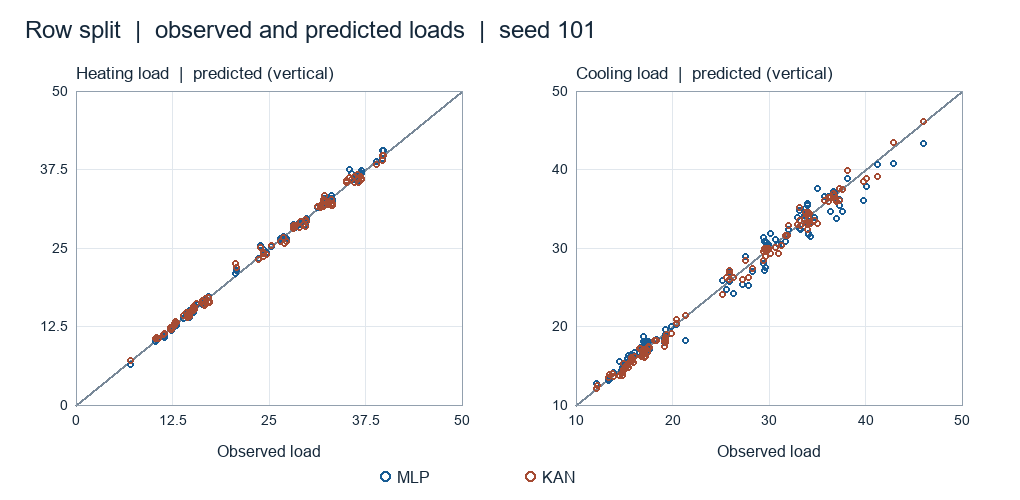

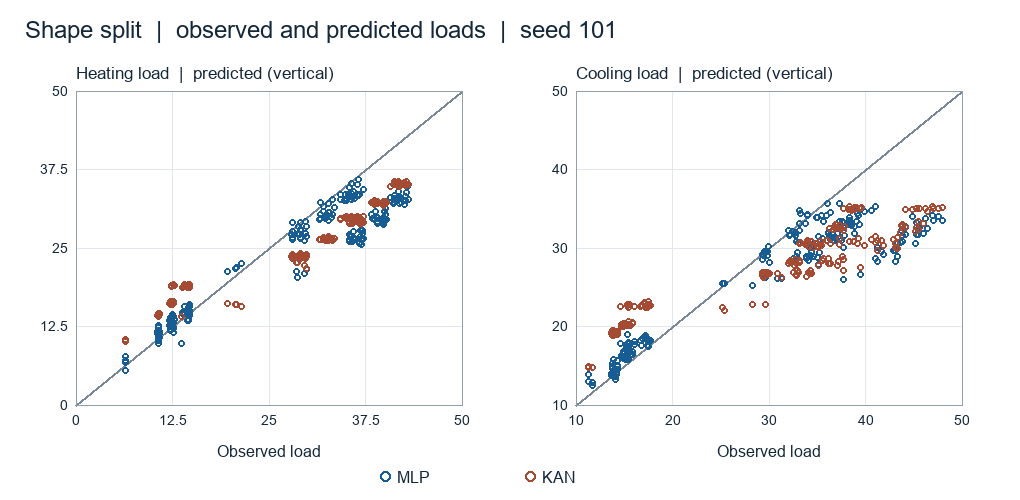

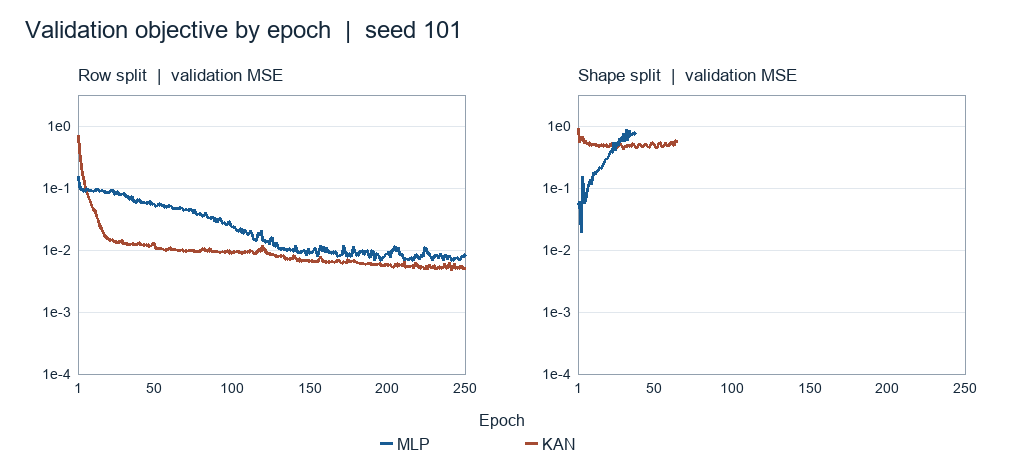

In [5]:
def show_png(path):
    renderer = globals().get("_notebook_image_renderer")
    if renderer:
        renderer(path)
    else:
        from IPython.display import Image as DisplayImage, display
        display(DisplayImage(filename=str(path)))

def font(size):
    try:
        return ImageFont.truetype("DejaVuSans.ttf", size)
    except OSError:
        try:
            return ImageFont.truetype("arial.ttf", size)
        except OSError:
            return ImageFont.load_default(size=size)

PALETTE = {"mlp": "#185C94", "kan": "#A54B33"}
INK = "#15283A"

def scatter_plot(protocol):
    image = Image.new("RGB", (1020, 500), "white")
    draw = ImageDraw.Draw(image)
    draw.text((25, 16), f"{protocol.title()} split  |  observed and predicted loads  |  seed 101",
              fill=INK, font=font(24))
    data = pred.query("protocol == @protocol and seed == 101")
    for j, target in enumerate(("heating", "cooling")):
        x0, y0, x1, y1 = 76+j*500, 91, 462+j*500, 405
        obs, estimates = f"{target}_actual", f"{target}_pred"
        lo = np.floor(data[[obs, estimates]].min().min()/10)*10
        hi = np.ceil(data[[obs, estimates]].max().max()/10)*10
        def xy(x, y):
            return (x0+(x-lo)/(hi-lo)*(x1-x0), y1-(y-lo)/(hi-lo)*(y1-y0))
        for tick in np.linspace(lo, hi, 5):
            tx, ty = xy(tick, tick)
            draw.line((tx,y0,tx,y1), fill="#E1E7ED")
            draw.line((x0,ty,x1,ty), fill="#E1E7ED")
            draw.text((tx, y1+10), f"{tick:g}", font=font(14), fill=INK, anchor="mt")
            draw.text((x0-8, ty), f"{tick:g}", font=font(14), fill=INK, anchor="rm")
        draw.line((*xy(lo,lo), *xy(hi,hi)), fill="#788898", width=2)
        draw.rectangle((x0,y0,x1,y1), outline="#92A0AE", width=1)
        for model, group in data.groupby("model", sort=False):
            for a, b in zip(group[obs], group[estimates], strict=True):
                px, py = xy(a,b)
                draw.ellipse((px-3,py-3,px+3,py+3), outline=PALETTE[model], width=2)
        draw.text((x0, 63), target.title() + " load  |  predicted (vertical)",
                  font=font(17), fill=INK)
        draw.text(((x0+x1)/2, 445), "Observed load", font=font(16), fill=INK, anchor="mt")
    for j, (model, color) in enumerate(PALETTE.items()):
        x = 380+145*j
        draw.ellipse((x,471,x+10,481), outline=color, width=2)
        draw.text((x+17,468), model.upper(), font=font(16), fill=INK)
    path = OUT / f"{protocol}_predictions.png"
    image.save(path)
    show_png(path)

def validation_plot():
    image = Image.new("RGB", (1020, 465), "white")
    draw = ImageDraw.Draw(image)
    draw.text((25, 16), "Validation objective by epoch  |  seed 101", font=font(24), fill=INK)
    for j, protocol in enumerate(SPLITS):
        x0,y0,x1,y1 = 78+j*500, 95, 465+j*500, 374
        data = curves.query("protocol == @protocol and seed == 101")
        lo, hi = -4.0, 0.5
        def xy(epoch, loss):
            return x0+(epoch-1)/(MAX_EPOCHS-1)*(x1-x0), y1-(np.log10(loss)-lo)/(hi-lo)*(y1-y0)
        for exponent in range(-4,1):
            _,ty = xy(1, 10.0**exponent)
            draw.line((x0,ty,x1,ty), fill="#E1E7ED")
            draw.text((x0-7,ty), f"1e{exponent}", fill=INK, font=font(14), anchor="rm")
        draw.rectangle((x0,y0,x1,y1), outline="#92A0AE")
        draw.text((x0,65), protocol.title()+" split  |  validation MSE", font=font(17), fill=INK)
        for ep in (1, 50, 100, 150, 200, 250):
            tx,_=xy(ep,1)
            draw.text((tx,y1+9), str(ep), font=font(14), fill=INK, anchor="mt")
        for model, group in data.groupby("model"):
            draw.line([xy(e,m) for e,m in zip(group.epoch, group.val_mse, strict=True)],
                      width=3, fill=PALETTE[model])
    draw.text((502, 414), "Epoch", font=font(16), fill=INK, anchor="mt")
    for j, (model, color) in enumerate(PALETTE.items()):
        x = 380+145*j
        draw.line((x,443,x+12,443), fill=color, width=3)
        draw.text((x+17,435), model.upper(), font=font(16), fill=INK)
    path = OUT / "validation_curves.png"
    image.save(path)
    show_png(path)

for protocol in SPLITS:
    scatter_plot(protocol)
validation_plot()